In [10]:
import os
import sys

# Must be set before rubin_sim/rubin_scheduler are imported: the value exported
# from ~/.bashrc points at a directory that does not exist.
os.environ["RUBIN_SIM_DATA_DIR"] = "/sdf/data/rubin/shared/rubin_sim_data"

# horseshoe_detailer.py lives one directory up
sys.path.insert(0, os.path.abspath(".."))

import numpy as np
import healpy as hp
import matplotlib.pylab as plt
%matplotlib inline
import rubin_sim.splat as splat
import copy 
from rubin_scheduler.utils import angular_separation
from horseshoe_detailer import HorseshoeAvoidanceDetailer

In [11]:
# use the detailer to load up the stellar catalog we are avoiding.
# The first positional arg is catalog_path (a FITS star catalog), not an
# opsim db -- leave it unset to get the default ybsc_v5.fits.
hsd = HorseshoeAvoidanceDetailer()

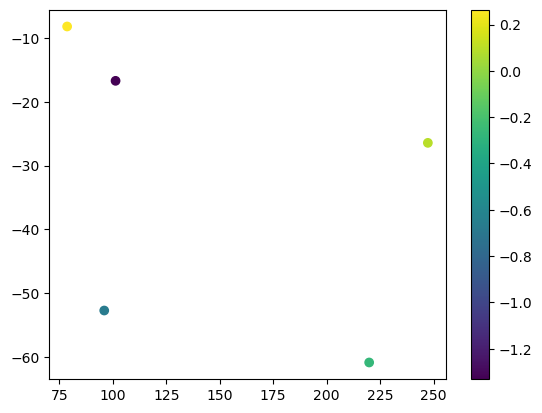

In [12]:

# The detailer only keeps the catalog as 3D unit vectors (self.xyz_stars),
# so recover RA/Dec from those rather than reading attributes it never sets.
star_dec_rad = np.arcsin(np.clip(hsd.xyz_stars[:, 2], -1.0, 1.0))
star_ra_rad = np.arctan2(hsd.xyz_stars[:, 1], hsd.xyz_stars[:, 0]) % (2 * np.pi)

# Let's just pick one of the really bright ones
star_indx = np.where((hsd.star_mags["r"] < 0.5) & (star_dec_rad < 0))
plt.scatter(np.degrees(star_ra_rad[star_indx]), np.degrees(star_dec_rad[star_indx]), c=hsd.star_mags["r"][star_indx])
cb = plt.colorbar()

ra = np.degrees(star_ra_rad[star_indx][0])
dec = np.degrees(star_dec_rad[star_indx][0])


In [13]:
# Define a report element that we want to run
class HighResSpotElement(splat.BaseReportElement):
    def compute_elements(self,visits_df=None, visits_array=None, nside=1024, band="r", ra=0., dec=0., radius=10.):
        
        sl = splat.Slicer(nside=nside)
        distance = angular_separation(visits_array["fieldRA"], visits_array["fieldDec"], ra, dec)
        info = {"data_source": self.run_name}
        info["observations_subset"] = self.subset + "\nband=%s\nDistance to point=%.2f deg" % (band, radius)

        metrics = []
        infos = []
        plot_dicts = []

        # Coadd depth
        metrics.append(splat.CoaddM5Metric(band))
        temp_info = copy.copy(info)
        temp_info["group"] = "Basics"
        temp_info["subgroup"] = "Coadd"
        infos.append(temp_info)
        plot_dicts.append({})

        # Number of visits
        metrics.append(splat.CountMetric())
        temp_info = copy.copy(info)
        temp_info["group"] = "Basics"
        temp_info["subgroup"] = "Counts"
        infos.append(temp_info)
        plot_dicts.append(
            {"log": True, "min": 1, "norm": "log", "cb_params": {"format": "%i", "n_ticks": 4}}
        )        
        sub_data = visits_array[np.where( (visits_array["band"] == band) & (distance <= radius))[0]]

        hp_arrays, infos = sl(sub_data, metrics, info=infos)

        return hp_arrays, infos, None

In [14]:
horse = HighResSpotElement("horseshoe_v5.3.7_10yrs.db")
h_hp_a, h_infos, _temp = horse(ra=ra, dec=dec)


In [15]:
# Not in this directory; read the baseline from the shared sim-data area.
baseline_db = (
    "/sdf/group/rubin/web_data/sim-data/sims_featureScheduler_runs5.3"
    "/baseline/baseline_v5.3.7_10yrs.db"
)
base = HighResSpotElement(baseline_db)
b_hp_arrays, b_infos, b_summaries = base(ra=ra, dec=dec)

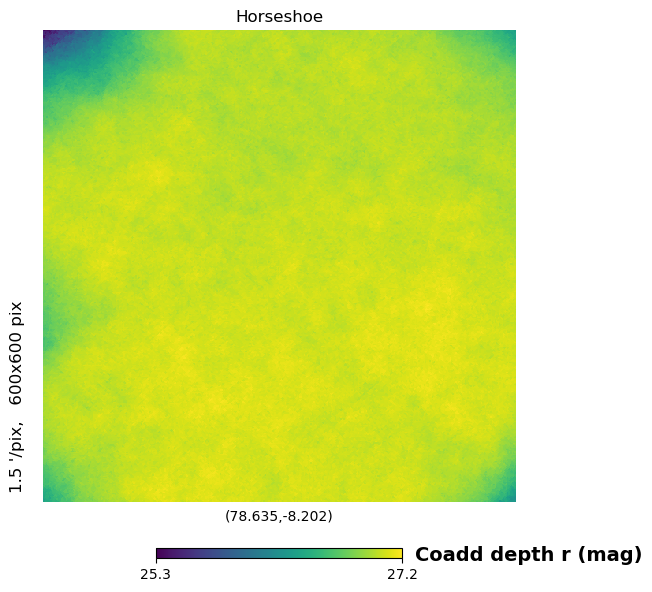

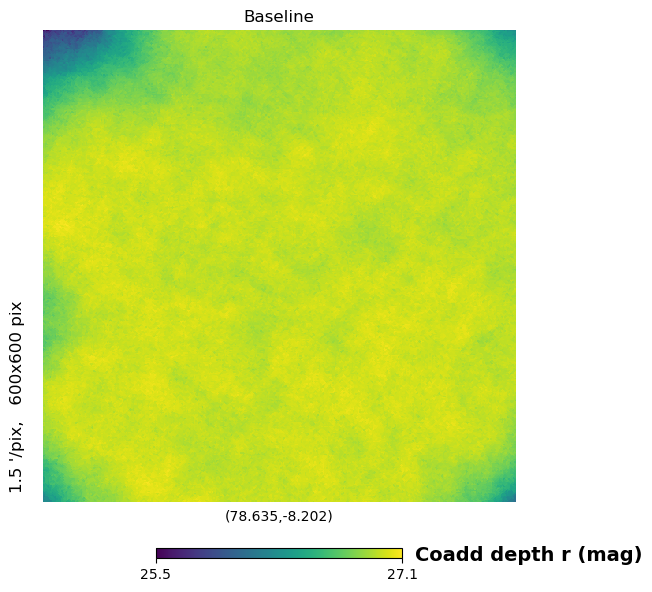

In [27]:
hp.gnomview(h_hp_a[0], rot=(ra,dec), title="Horseshoe", xsize=600, unit="Coadd depth r (mag)")
hp.gnomview(b_hp_arrays[0], rot=(ra,dec), title="Baseline", xsize=600, unit="Coadd depth r (mag)")

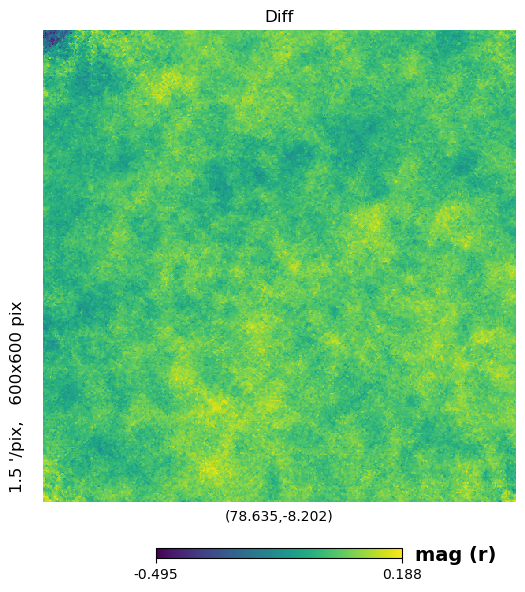

In [26]:
hp.gnomview(h_hp_a[0] -b_hp_arrays[0] , rot=(ra,dec), title="Diff", unit="mag (r)", xsize=600)

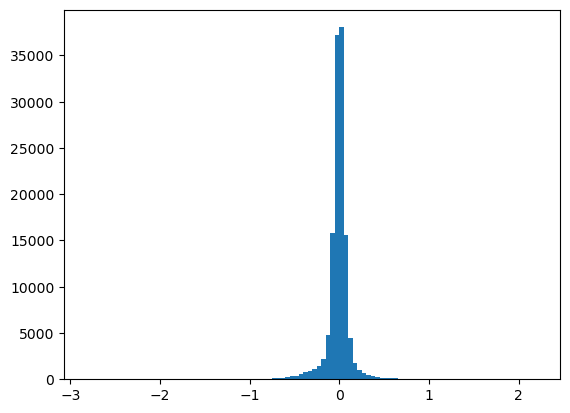

In [18]:
_temp = plt.hist(h_hp_a[0] -b_hp_arrays[0], bins=100)

---
# Confronto baseline vs horseshoe

Le celle sopra guardano un singolo spot ad alta risoluzione. Qui sotto si
quantifica l'efficacia del detailer su **tutta** la survey a 10 anni:

1. quante visite restano *compromesse* (stella brillante nell'anello proibito);
2. come si distribuisce il residuo per banda e per magnitudine stellare;
3. quanto costa in profondità e conteggi intorno alla stella di test.

In [21]:
import sqlite3
import pandas as pd

# Carica RA/Dec/banda di tutte le visite delle due survey.
# fieldRA/fieldDec nel db sono in GRADI, check_pointings vuole RADIANTI.
def load_pointings(db_path):
    con = sqlite3.connect("file:%s?mode=ro" % db_path, uri=True)
    df = pd.read_sql("select fieldRA, fieldDec, band, night, fiveSigmaDepth from observations;", con)
    con.close()
    return df

runs = {
    "baseline": load_pointings(baseline_db),
    "horseshoe": load_pointings("horseshoe_v5.3.7_10yrs.db"),
}

for name, df in runs.items():
    print("%-10s %d visite" % (name, len(df)))

baseline   1809598 visite
horseshoe  1809684 visite


In [22]:
# Applica lo stesso criterio del detailer a entrambe le survey: una visita e'
# "compromessa" se una stella sopra il limite di magnitudine cade nell'anello
# proibito (inner_radius_deg .. outer_radius_deg) attorno al puntamento.
# ~25 s per survey.
results = {}
for name, df in runs.items():
    compromised, hit_info = hsd.check_pointings(
        np.radians(df["fieldRA"].values),
        np.radians(df["fieldDec"].values),
        bands=df["band"].values,
    )
    results[name] = {"compromised": compromised, "hit_info": hit_info}
    print("%-10s compromesse = %5d / %d  (%.4f%%)"
          % (name, compromised.sum(), len(compromised), 100 * compromised.mean()))

n_base = results["baseline"]["compromised"].sum()
n_horse = results["horseshoe"]["compromised"].sum()
print("\nriduzione: %d -> %d  (%.1f%% in meno)"
      % (n_base, n_horse, 100 * (1 - n_horse / n_base)))

baseline   compromesse =  5919 / 1809598  (0.3271%)
horseshoe  compromesse =   863 / 1809684  (0.0477%)

riduzione: 5919 -> 863  (85.4% in meno)


tasso residuo per banda (%): {'u': np.float64(0.0433), 'g': np.float64(0.019), 'r': np.float64(0.0376), 'i': np.float64(0.0485), 'z': np.float64(0.0639), 'y': np.float64(0.0611)}


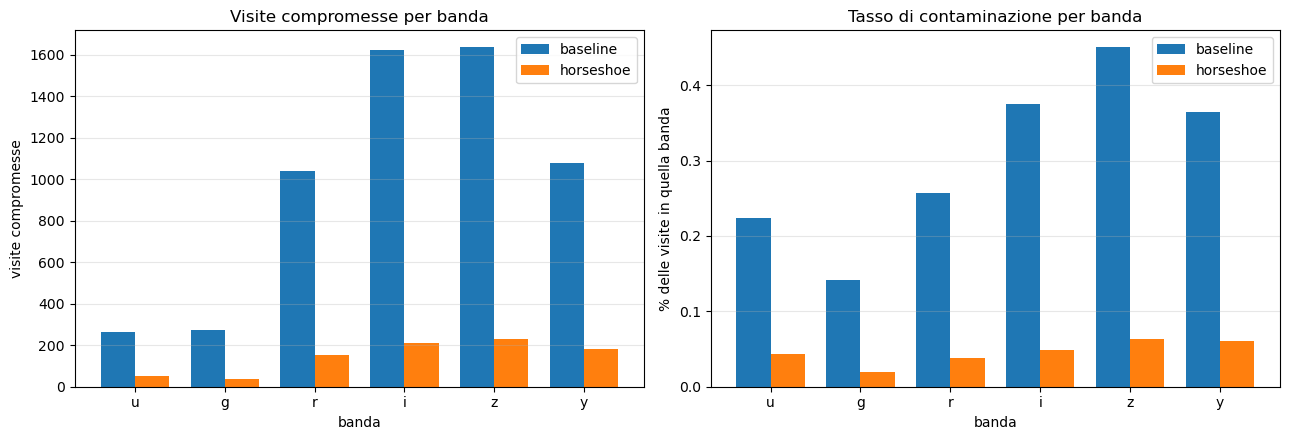

In [23]:
# Breakdown per banda: numero assoluto e tasso (compromesse / visite in banda).
# Il tasso conta perche' le bande hanno numeri di visite molto diversi.
bands = ["u", "g", "r", "i", "z", "y"]
x = np.arange(len(bands))
w = 0.38

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(13, 4.5))

for k, (name, off) in enumerate([("baseline", -w / 2), ("horseshoe", w / 2)]):
    df = runs[name]
    comp = results[name]["compromised"]
    counts, rates = [], []
    for b in bands:
        in_band = (df["band"].values == b)
        counts.append(comp[in_band].sum())
        rates.append(100 * comp[in_band].mean() if in_band.sum() else 0.0)
    ax1.bar(x + off, counts, w, label=name)
    ax2.bar(x + off, rates, w, label=name)
    if name == "horseshoe":
        print("tasso residuo per banda (%):",
              {b: round(r, 4) for b, r in zip(bands, rates)})

ax1.set_ylabel("visite compromesse")
ax1.set_title("Visite compromesse per banda")
ax2.set_ylabel("% delle visite in quella banda")
ax2.set_title("Tasso di contaminazione per banda")
for a in (ax1, ax2):
    a.set_xticks(x)
    a.set_xticklabels(bands)
    a.set_xlabel("banda")
    a.legend()
    a.grid(alpha=0.3, axis="y")
plt.tight_layout()

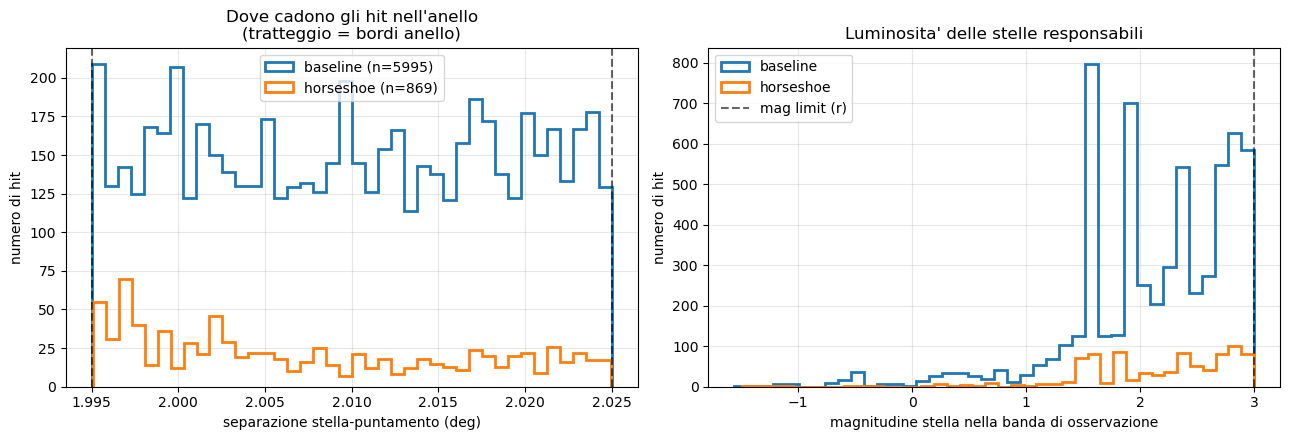

In [24]:
# Proprieta' degli "hit" residui: separazione angolare e magnitudine della
# stella colpevole. Mostra SE il residuo e' concentrato ai bordi dell'anello
# (quasi-miss, poco preoccupante) o ben dentro (il detailer non li ha presi).
def hit_table(name):
    rows = [h for hits in results[name]["hit_info"] for h in hits]
    return pd.DataFrame(rows)

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(13, 4.5))
for name in ("baseline", "horseshoe"):
    t = hit_table(name)
    if len(t) == 0:
        continue
    ax1.hist(t["sep_deg"], bins=40, histtype="step", lw=2, label="%s (n=%d)" % (name, len(t)))
    ax2.hist(t["star_mag_band"], bins=40, histtype="step", lw=2, label=name)

for xv in (hsd.inner_radius_deg, hsd.outer_radius_deg):
    ax1.axvline(xv, color="k", ls="--", alpha=0.6)
ax1.set_xlabel("separazione stella-puntamento (deg)")
ax1.set_ylabel("numero di hit")
ax1.set_title("Dove cadono gli hit nell'anello\n(tratteggio = bordi anello)")

ax2.axvline(hsd.get_mag_limit("r"), color="k", ls="--", alpha=0.6,
            label="mag limit (r)")
ax2.set_xlabel("magnitudine stella nella banda di osservazione")
ax2.set_ylabel("numero di hit")
ax2.set_title("Luminosita' delle stelle responsabili")

for a in (ax1, ax2):
    a.legend()
    a.grid(alpha=0.3)
plt.tight_layout()